In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# ============================================================
# Train / Test 분할 검증
#   ① 분할 자체의 무결성  ② 결함 유형 비율 유지 여부
# ============================================================
import sys
from pathlib import Path

BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "src" / "config.py").exists())
sys.path.insert(0, str(BASE_DIR / "src"))

import pandas as pd

TARGETS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
           "Dirtiness", "Bumps", "Other_Faults"]

df = pd.read_csv(BASE_DIR / "data" / "raw" / "Faults.csv")
tr = pd.read_csv(BASE_DIR / "data" / "split" / "train_idx.csv")["index"]
te = pd.read_csv(BASE_DIR / "data" / "split" / "test_idx.csv")["index"]

y_all = df[TARGETS].idxmax(axis=1)

# ---------- ① 분할 무결성 ----------
checks = {
    "Train과 Test에 겹치는 행": len(set(tr) & set(te)),
    "누락된 행": len(df) - len(set(tr) | set(te)),
    "Train 내 중복 인덱스": len(tr) - tr.nunique(),
    "Test 내 중복 인덱스": len(te) - te.nunique(),
    "범위를 벗어난 인덱스": int((pd.concat([tr, te]) >= len(df)).sum()),
    "타깃 열 합이 1이 아닌 행": int((df[TARGETS].sum(axis=1) != 1).sum()),
}
print("=" * 55)
print("① 분할 무결성 검사  (모두 0이어야 정상)")
print("=" * 55)
for k, v in checks.items():
    print(f"  {'OK ' if v == 0 else 'NG '} {k:28s}: {v}")

print(f"\n  Train {len(tr)}건 / Test {len(te)}건 "
      f"| Test 비율 {len(te)/len(df):.4f}")

# ---------- ② 결함 유형 비율 ----------
tab = pd.DataFrame({
    "원본 비율": y_all.value_counts(normalize=True),
    "Train 비율": y_all.loc[tr].value_counts(normalize=True),
    "Test 비율": y_all.loc[te].value_counts(normalize=True),
}).round(4)

tab.insert(0, "Test 건수", y_all.loc[te].value_counts())
tab.insert(0, "Train 건수", y_all.loc[tr].value_counts())
tab["원본과의 최대 차이"] = (
    tab[["Train 비율", "Test 비율"]]
    .sub(tab["원본 비율"], axis=0).abs().max(axis=1).round(4)
)

print("\n" + "=" * 55)
print("② 결함 유형별 비율 비교")
print("=" * 55)
print(tab.loc[TARGETS].to_string())

worst = tab["원본과의 최대 차이"].max()
print(f"\n  최대 차이: {worst:.4f}  →  ", end="")
print("층화 분할 정상" if worst < 0.01 else "확인 필요")

# ---------- ③ 소수 클래스 경고 ----------
small = tab[tab["Test 건수"] < 20]
if len(small):
    print("\n" + "=" * 55)
    print("③ 평가 데이터가 20건 미만인 유형 (성능 수치가 불안정)")
    print("=" * 55)
    for name, row in small.iterrows():
        step = 1 / row["Test 건수"]
        print(f"  {name:13s} Test {int(row['Test 건수']):3d}건 "
              f"→ 1건 차이로 재현율이 {step:.3f} 움직임")

① 분할 무결성 검사  (모두 0이어야 정상)
  OK  Train과 Test에 겹치는 행          : 0
  OK  누락된 행                       : 0
  OK  Train 내 중복 인덱스              : 0
  OK  Test 내 중복 인덱스               : 0
  OK  범위를 벗어난 인덱스                 : 0
  OK  타깃 열 합이 1이 아닌 행             : 0

  Train 1552건 / Test 389건 | Test 비율 0.2004

② 결함 유형별 비율 비교
              Train 건수  Test 건수   원본 비율  Train 비율  Test 비율  원본과의 최대 차이
Pastry             126       32  0.0814    0.0812   0.0823      0.0009
Z_Scratch          152       38  0.0979    0.0979   0.0977      0.0002
K_Scatch           313       78  0.2014    0.2017   0.2005      0.0009
Stains              58       14  0.0371    0.0374   0.0360      0.0011
Dirtiness           44       11  0.0283    0.0284   0.0283      0.0001
Bumps              321       81  0.2071    0.2068   0.2082      0.0011
Other_Faults       538      135  0.3467    0.3466   0.3470      0.0003

  최대 차이: 0.0011  →  층화 분할 정상

③ 평가 데이터가 20건 미만인 유형 (성능 수치가 불안정)
  Stains        Test  14건 → 1건 차이로 재현율이 0.071 움직임
  D

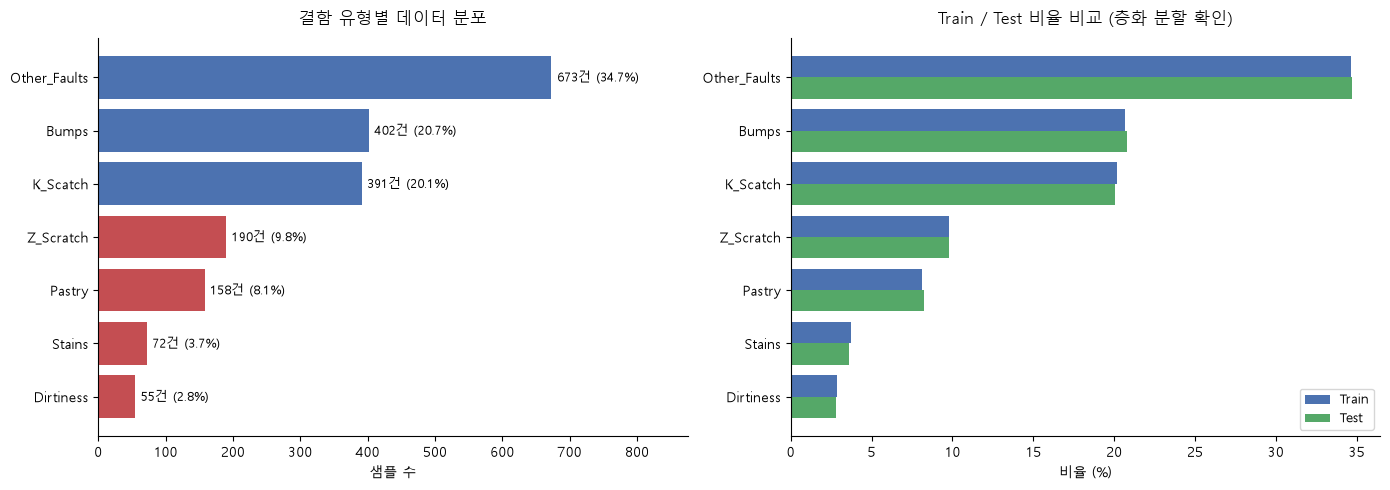

In [3]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

order = y_all.value_counts().sort_values().index
BLUE, RED, GREEN = "#4C72B0", "#C44E52", "#55A868"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 왼쪽: 전체 분포
cnt = y_all.value_counts()[order]
ratio = cnt / cnt.sum() * 100
colors = [RED if r < 10 else BLUE for r in ratio]
b = axes[0].barh(cnt.index, cnt.values, color=colors)
axes[0].bar_label(b, labels=[f"{n}건 ({r:.1f}%)" for n, r in zip(cnt, ratio)],
                  padding=4, fontsize=9)
axes[0].set_xlabel("샘플 수")
axes[0].set_xlim(0, cnt.max() * 1.3)
axes[0].set_title("결함 유형별 데이터 분포", fontsize=12, pad=10)
axes[0].spines[["top", "right"]].set_visible(False)

# 오른쪽: Train/Test 비율 일치 확인
yy = range(len(order))
axes[1].barh([i + 0.2 for i in yy],
             y_all.loc[tr].value_counts(normalize=True)[order] * 100,
             height=0.4, color=BLUE, label="Train")
axes[1].barh([i - 0.2 for i in yy],
             y_all.loc[te].value_counts(normalize=True)[order] * 100,
             height=0.4, color=GREEN, label="Test")
axes[1].set_yticks(list(yy))
axes[1].set_yticklabels(order)
axes[1].set_xlabel("비율 (%)")
axes[1].set_title("Train / Test 비율 비교 (층화 분할 확인)", fontsize=12, pad=10)
axes[1].legend(loc="lower right", fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
# ============================================================
# 선택적 SMOTE: 희귀 유형(Stains, Dirtiness)에만 적용
# ============================================================
import sys
from pathlib import Path

BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "src" / "config.py").exists())
sys.path.insert(0, str(BASE_DIR / "src"))

import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, accuracy_score
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import SMOTE

from load_data import load_data
from config import CV, RANDOM_STATE as R

X_train, X_test, y_train, y_test = load_data()
CLASSES = sorted(y_train.unique())
RARE = ["Stains", "Dirtiness"]

# 폴드 안에서의 실제 학습 샘플 수 = 전체의 4/5
fold_counts = (y_train.value_counts() * 0.8).astype(int)
print("5-fold 학습 시 각 폴드의 유형별 샘플 수 (근사)")
print(fold_counts.to_string(), "\n")


def gb():
    return GradientBoostingClassifier(random_state=R)


def evaluate(name, model):
    pred = cross_val_predict(model, X_train, y_train, cv=CV, n_jobs=-1)
    row = {
        "실험명": name,
        "Macro F1": round(f1_score(y_train, pred, average="macro"), 4),
        "정확도": round(accuracy_score(y_train, pred), 4),
    }
    for c in CLASSES:
        row[c] = round(f1_score(y_train == c, pred == c), 3)
    print(f"  {name} 완료")
    return row


rows = [evaluate("처리 없음", gb())]

# --- 희귀 2종만, 목표치를 바꿔가며 ---------------------------
for target in [80, 120, 180]:
    strategy = {c: target for c in RARE}          # 지정한 유형만 늘림
    rows.append(evaluate(
        f"희귀 2종만 SMOTE → {target}건",
        imb_pipeline(SMOTE(sampling_strategy=strategy,
                           k_neighbors=3, random_state=R), gb())
    ))

# --- 비교군: 전체 유형에 SMOTE -------------------------------
rows.append(evaluate(
    "전체 SMOTE (비교군)",
    imb_pipeline(SMOTE(k_neighbors=3, random_state=R), gb())
))

res = pd.DataFrame(rows)
print("\n=== 결과 ===")
print(res.to_string(index=False))

# 희귀 유형만 따로
print("\n=== 희귀 유형 집중 비교 ===")
print(res[["실험명", "Macro F1", "Stains", "Dirtiness"]].to_string(index=False))

5-fold 학습 시 각 폴드의 유형별 샘플 수 (근사)
target
Other_Faults    430
Bumps           256
K_Scratch       250
Z_Scratch       121
Pastry          100
Stains           46
Dirtiness        35 

  처리 없음 완료
  희귀 2종만 SMOTE → 80건 완료
  희귀 2종만 SMOTE → 120건 완료
  희귀 2종만 SMOTE → 180건 완료
  전체 SMOTE (비교군) 완료

=== 결과 ===
                실험명  Macro F1    정확도  Bumps  Dirtiness  K_Scratch  Other_Faults  Pastry  Stains  Z_Scratch
              처리 없음    0.7960 0.7784  0.657      0.810      0.961         0.733   0.563   0.912      0.936
 희귀 2종만 SMOTE → 80건    0.8028 0.7809  0.661      0.857      0.960         0.734   0.563   0.904      0.940
희귀 2종만 SMOTE → 120건    0.8059 0.7790  0.660      0.878      0.958         0.728   0.570   0.904      0.943
희귀 2종만 SMOTE → 180건    0.8010 0.7784  0.657      0.824      0.958         0.728   0.563   0.931      0.946
     전체 SMOTE (비교군)    0.8093 0.7829  0.685      0.826      0.952         0.725   0.630   0.940      0.907

=== 희귀 유형 집중 비교 ===
                실험명  Macro F1  Stains  

In [5]:
# Bumps와 Other_Faults는 최다 유형이라 SMOTE 대상이 아님
# → 대신 성능이 가장 낮은 Pastry를 보강해보기
rows2 = [
    evaluate("처리 없음", gb()),
    evaluate("Pastry만 SMOTE → 250건",
             imb_pipeline(SMOTE(sampling_strategy={"Pastry": 250},
                                k_neighbors=3, random_state=R), gb())),
]
print(pd.DataFrame(rows2)[["실험명", "Macro F1", "Pastry"]].to_string(index=False))

  처리 없음 완료
  Pastry만 SMOTE → 250건 완료
                 실험명  Macro F1  Pastry
               처리 없음    0.7960   0.563
Pastry만 SMOTE → 250건    0.8031   0.652


In [6]:
rows2 = [
    evaluate("처리 없음", gb()),
    evaluate("전체 SMOTE", imb_pipeline(
        SMOTE(k_neighbors=3, random_state=R), gb())),
    evaluate("Pastry만 → 200건", imb_pipeline(
        SMOTE(sampling_strategy={"Pastry": 200},
              k_neighbors=3, random_state=R), gb())),
    evaluate("Pastry 200 + Dirtiness 120", imb_pipeline(
        SMOTE(sampling_strategy={"Pastry": 200, "Dirtiness": 120},
              k_neighbors=3, random_state=R), gb())),
    evaluate("저성능 3종 (Pastry 200, Bumps 320, Dirtiness 120)", imb_pipeline(
        SMOTE(sampling_strategy={"Pastry": 200, "Bumps": 320,
                                 "Dirtiness": 120},
              k_neighbors=3, random_state=R), gb())),
]

res2 = pd.DataFrame(rows2)
print(res2[["실험명", "Macro F1", "Pastry", "Bumps", "Dirtiness"]]
      .to_string(index=False))

  처리 없음 완료
  전체 SMOTE 완료
  Pastry만 → 200건 완료
  Pastry 200 + Dirtiness 120 완료
  저성능 3종 (Pastry 200, Bumps 320, Dirtiness 120) 완료
                                          실험명  Macro F1  Pastry  Bumps  Dirtiness
                                        처리 없음    0.7960   0.563  0.657      0.810
                                     전체 SMOTE    0.8093   0.630  0.685      0.826
                               Pastry만 → 200건    0.8082   0.639  0.660      0.805
                   Pastry 200 + Dirtiness 120    0.8062   0.629  0.650      0.847
저성능 3종 (Pastry 200, Bumps 320, Dirtiness 120)    0.8138   0.584  0.679      0.860


In [7]:
# ============================================================
# GB + XGBoost 소프트 보팅 앙상블
# ============================================================
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "src" / "config.py").exists())
sys.path.insert(0, str(BASE_DIR / "src"))

import numpy as np
import pandas as pd
from sklearn.ensemble import VotingClassifier, GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import BorderlineSMOTE
from xgboost import XGBClassifier

from load_data import load_data
from config import CV, RANDOM_STATE

X_train, X_test, y_train, y_test = load_data()

# XGBoost는 문자열 라벨을 못 받으므로 숫자로 변환
le = LabelEncoder()
ye = pd.Series(le.fit_transform(y_train), index=y_train.index)


def bs():
    return BorderlineSMOTE(k_neighbors=3, m_neighbors=5,
                           random_state=RANDOM_STATE)


ensemble = VotingClassifier(
    estimators=[
        ("gb", imb_pipeline(bs(), GradientBoostingClassifier(
            random_state=RANDOM_STATE))),
        ("xgb", imb_pipeline(bs(), XGBClassifier(
            n_estimators=500, learning_rate=0.1, max_depth=6,
            random_state=RANDOM_STATE, n_jobs=1, eval_metric="mlogloss"))),
    ],
    voting="soft",
)

print("학습 중... 2~4분 걸립니다.")
pred_num = cross_val_predict(ensemble, X_train, ye, cv=CV, n_jobs=-1)

# 숫자 → 원래 결함 이름으로 되돌리기
pred = le.inverse_transform(pred_num)

print("\n=== GB + XGBoost 소프트 보팅 ===")
print("Macro F1   :", round(f1_score(y_train, pred, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_train, pred, average="weighted"), 4))
print("정확도      :", round(accuracy_score(y_train, pred), 4))
print()
print(classification_report(y_train, pred, digits=3))

학습 중... 2~4분 걸립니다.

=== GB + XGBoost 소프트 보팅 ===
Macro F1   : 0.8249
Weighted F1: 0.8014
정확도      : 0.8015

              precision    recall  f1-score   support

       Bumps      0.674     0.729     0.701       321
   Dirtiness      0.857     0.818     0.837        44
   K_Scratch      0.959     0.971     0.965       313
Other_Faults      0.775     0.723     0.748       538
      Pastry      0.641     0.651     0.646       126
      Stains      0.933     0.966     0.949        58
   Z_Scratch      0.917     0.941     0.929       152

    accuracy                          0.802      1552
   macro avg      0.822     0.828     0.825      1552
weighted avg      0.802     0.802     0.801      1552



In [8]:
RESULT_PATH = BASE_DIR / "results" / "model_scores.csv"
RESULT_PATH.parent.mkdir(parents=True, exist_ok=True)

row = {
    "실험명": "GB+XGB_BorderlineSMOTE_SoftVoting",
    "담당자": "박태상",
    "Macro_F1": round(f1_score(y_train, pred, average="macro"), 4),
    "Weighted_F1": round(f1_score(y_train, pred, average="weighted"), 4),
    "정확도": round(accuracy_score(y_train, pred), 4),
    "비고": "BorderlineSMOTE + 소프트보팅 (학습데이터 5-fold)",
}

new = pd.DataFrame([row])

# 기존 파일을 읽되, 형식이 다르면 백업하고 새로 시작
if RESULT_PATH.exists() and RESULT_PATH.stat().st_size > 0:
    try:
        prev = pd.read_csv(RESULT_PATH)
    except Exception:
        prev = pd.DataFrame()

    if "실험명" in prev.columns:
        prev = prev[prev["실험명"] != row["실험명"]]     # 같은 실험명은 갱신
        out = pd.concat([prev, new], ignore_index=True)
    elif len(prev):
        backup = RESULT_PATH.with_name("model_scores_backup.csv")
        prev.to_csv(backup, index=False, encoding="utf-8-sig")
        print(f"형식이 달라 기존 파일을 백업했습니다 → {backup.name}")
        print(f"  기존 열: {list(prev.columns)}")
        out = new
    else:
        out = new
else:
    out = new

out.to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")
print("\n=== 누적 결과 ===")
print(out.sort_values("Macro_F1", ascending=False).to_string(index=False))


=== 누적 결과 ===
                              실험명 담당자  Macro_F1  Weighted_F1    정확도                                     비고
GB+XGB_BorderlineSMOTE_SoftVoting 박태상    0.8249       0.8014 0.8015 BorderlineSMOTE + 소프트보팅 (학습데이터 5-fold)
               GB_BorderlineSMOTE 박태상    0.8117          NaN    NaN                             경계 집중 과대표집
                      GB_baseline 박태상    0.7960          NaN 0.7784        GradientBoosting 기본값, 불균형 처리 없음


In [9]:
RESULT_PATH = BASE_DIR / "results" / "model_scores.csv"

print("파일 존재:", RESULT_PATH.exists())
if RESULT_PATH.exists():
    print("크기:", RESULT_PATH.stat().st_size, "바이트")
    tmp = pd.read_csv(RESULT_PATH)
    print("열 이름:", list(tmp.columns))
    print(tmp.to_string())

파일 존재: True
크기: 344 바이트
열 이름: ['실험명', '담당자', 'Macro_F1', 'Weighted_F1', '정확도', '비고']
                                 실험명  담당자  Macro_F1  Weighted_F1     정확도                                      비고
0                        GB_baseline  박태상    0.7960          NaN  0.7784         GradientBoosting 기본값, 불균형 처리 없음
1                 GB_BorderlineSMOTE  박태상    0.8117          NaN     NaN                              경계 집중 과대표집
2  GB+XGB_BorderlineSMOTE_SoftVoting  박태상    0.8249       0.8014  0.8015  BorderlineSMOTE + 소프트보팅 (학습데이터 5-fold)


In [10]:
results = [
    {"실험명": "GB_baseline", "담당자": "박태상",
     "Macro_F1": 0.7960, "Weighted_F1": None, "정확도": 0.7784,
     "비고": "GradientBoosting 기본값, 불균형 처리 없음"},
    {"실험명": "GB_BorderlineSMOTE", "담당자": "박태상",
     "Macro_F1": 0.8117, "Weighted_F1": None, "정확도": None,
     "비고": "경계 집중 과대표집"},
    {"실험명": "GB+XGB_BorderlineSMOTE_SoftVoting", "담당자": "박태상",
     "Macro_F1": 0.8249, "Weighted_F1": 0.8014, "정확도": 0.8015,
     "비고": "소프트 보팅 앙상블"},
]

out = pd.DataFrame(results)
out.to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")
print(out.sort_values("Macro_F1", ascending=False).to_string(index=False))

                              실험명 담당자  Macro_F1  Weighted_F1    정확도                              비고
GB+XGB_BorderlineSMOTE_SoftVoting 박태상    0.8249       0.8014 0.8015                      소프트 보팅 앙상블
               GB_BorderlineSMOTE 박태상    0.8117          NaN    NaN                      경계 집중 과대표집
                      GB_baseline 박태상    0.7960          NaN 0.7784 GradientBoosting 기본값, 불균형 처리 없음


In [11]:
RESULT_PATH = BASE_DIR / "results" / "model_scores.csv"
RESULT_PATH.parent.mkdir(parents=True, exist_ok=True)

# 기존 내용을 표준 양식으로 재작성
records = [
    {"실험명": "GB_baseline",
     "담당자": "박태상",
     "Macro_F1": 0.7960, "Weighted_F1": None, "정확도": 0.7784,
     "비고": "GradientBoosting 기본값, 불균형 처리 없음"},

    {"실험명": "GB_BorderlineSMOTE",
     "담당자": "박태상",
     "Macro_F1": 0.8117, "Weighted_F1": None, "정확도": None,
     "비고": "경계 집중 과대표집"},

    {"실험명": "GB+XGB_BorderlineSMOTE_SoftVoting",
     "담당자": "박태상",
     "Macro_F1": 0.8249, "Weighted_F1": 0.8014, "정확도": 0.8015,
     "비고": "소프트 보팅 앙상블"},
]

out = pd.DataFrame(records)
out.to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")

print(pd.read_csv(RESULT_PATH).to_string(index=False))

                              실험명 담당자  Macro_F1  Weighted_F1    정확도                              비고
                      GB_baseline 박태상    0.7960          NaN 0.7784 GradientBoosting 기본값, 불균형 처리 없음
               GB_BorderlineSMOTE 박태상    0.8117          NaN    NaN                      경계 집중 과대표집
GB+XGB_BorderlineSMOTE_SoftVoting 박태상    0.8249       0.8014 0.8015                      소프트 보팅 앙상블


In [12]:
%pip install evaluate

Note: you may need to restart the kernel to use updated packages.


In [13]:
import evaluate
print([x for x in dir(evaluate) if not x.startswith("_")])

['BASE_DIR', 'COLUMNS', 'Path', 'RESULT_PATH', 'accuracy_score', 'f1_score', 'log_result', 'pd', 'results_table']


In [14]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

RESULT_PATH = BASE_DIR / "results" / "model_scores.csv"
RESULT_PATH.parent.mkdir(parents=True, exist_ok=True)
COLUMNS = ["실험명", "담당자", "Macro_F1", "Weighted_F1", "정확도", "비고"]

records = [
    {"실험명": "GB_baseline", "담당자": "박태상",
     "Macro_F1": 0.7960, "Weighted_F1": None, "정확도": 0.7784,
     "비고": "GradientBoosting 기본값, 불균형 처리 없음"},
    {"실험명": "GB_BorderlineSMOTE", "담당자": "박태상",
     "Macro_F1": 0.8117, "Weighted_F1": None, "정확도": None,
     "비고": "경계 집중 과대표집"},
    {"실험명": "GB+XGB_BorderlineSMOTE_SoftVoting", "담당자": "박태상",
     "Macro_F1": round(f1_score(y_train, pred, average="macro"), 4),
     "Weighted_F1": round(f1_score(y_train, pred, average="weighted"), 4),
     "정확도": round(accuracy_score(y_train, pred), 4),
     "비고": "소프트 보팅 앙상블"},
]

out = pd.DataFrame(records).reindex(columns=COLUMNS)
out.to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")

print(pd.read_csv(RESULT_PATH).to_string(index=False))

                              실험명 담당자  Macro_F1  Weighted_F1    정확도                              비고
                      GB_baseline 박태상    0.7960          NaN 0.7784 GradientBoosting 기본값, 불균형 처리 없음
               GB_BorderlineSMOTE 박태상    0.8117          NaN    NaN                      경계 집중 과대표집
GB+XGB_BorderlineSMOTE_SoftVoting 박태상    0.8249       0.8014 0.8015                      소프트 보팅 앙상블
